# Práctica — Análisis y ajuste de un Algoritmo Genético
## Fundamentos de Inteligencia Artificial

Este Colab contiene la **función objetivo y el Algoritmo Genético base**.

Todos los experimentos deberán realizarse llamando funciones y modificando únicamente sus parámetros.

**Función:** `f(x) = 0.6x + 10 sin(1.4x) + 9`, con `0 <= x <= 22`.

**Objetivo:** maximizar `f(x)`.


## 1. Librerías


In [14]:
import math
import random
import matplotlib.pyplot as plt


## 2. Función objetivo


In [15]:
def funcion_objetivo(x):
    return 0.6 * x + 10 * math.sin(1.4 * x) + 9


## 3. Funciones del Algoritmo Genético


In [16]:
# Dominio del problema
X_MIN = 0.0
X_MAX = 22.0

def generar_poblacion(tamano):
    return [random.uniform(X_MIN, X_MAX) for _ in range(tamano)]

def fitness(x):
    return funcion_objetivo(x)

def seleccion_torneo(poblacion, k=3):
    candidatos = random.sample(poblacion, min(k, len(poblacion)))
    return max(candidatos, key=fitness)

def seleccion_ruleta(poblacion):
    valores = [fitness(x) for x in poblacion]
    minimo = min(valores)
    # Desplazamiento para garantizar pesos positivos.
    pesos = [(v - minimo) + 1e-6 for v in valores]
    return random.choices(poblacion, weights=pesos, k=1)[0]

def seleccionar(poblacion, metodo='torneo'):
    if metodo.lower() == 'torneo':
        return seleccion_torneo(poblacion)
    elif metodo.lower() == 'ruleta':
        return seleccion_ruleta(poblacion)
    else:
        raise ValueError("seleccion debe ser 'torneo' o 'ruleta'")

def cruzamiento(padre1, padre2):
    # Cruzamiento aritmético para individuos reales.
    a = random.random()
    hijo = a * padre1 + (1-a) * padre2
    return max(X_MIN, min(X_MAX, hijo))

def mutar(individuo, prob_mutacion):
    if random.random() < prob_mutacion:
        # Pequeña perturbación aleatoria.
        individuo += random.uniform(-2.0, 2.0)
    return max(X_MIN, min(X_MAX, individuo))


## 4. Algoritmo Genético general


In [17]:
def algoritmo_genetico(
    tamano_poblacion=20,
    generaciones=30,
    prob_mutacion=0.10,
    seleccion='torneo',
    elitismo=1,
    semilla=42
):
    random.seed(semilla)

    poblacion = generar_poblacion(tamano_poblacion)
    historial = []
    mejor_global = max(poblacion, key=fitness)
    generacion_mejor = 0

    for gen in range(generaciones):
        poblacion.sort(key=fitness, reverse=True)
        mejor_gen = poblacion[0]
        historial.append(fitness(mejor_gen))

        if fitness(mejor_gen) > fitness(mejor_global):
            mejor_global = mejor_gen
            generacion_mejor = gen

        # Conservar los mejores individuos.
        n_elite = max(0, min(int(elitismo), tamano_poblacion))
        nueva = poblacion[:n_elite]

        while len(nueva) < tamano_poblacion:
            p1 = seleccionar(poblacion, seleccion)
            p2 = seleccionar(poblacion, seleccion)
            hijo = cruzamiento(p1, p2)
            hijo = mutar(hijo, prob_mutacion)
            nueva.append(hijo)

        poblacion = nueva

    # Evaluar también la última población generada.
    candidato_final = max(poblacion, key=fitness)
    if fitness(candidato_final) > fitness(mejor_global):
        mejor_global = candidato_final
        generacion_mejor = generaciones

    return {
        'mejor_x': mejor_global,
        'mejor_fitness': fitness(mejor_global),
        'generacion_mejor': generacion_mejor,
        'historial': historial
    }


## 5. Funciones auxiliares para los experimentos


In [18]:
def mostrar_resultado(resultado):
    print('Mejor x:', round(resultado['mejor_x'], 5))
    print('Mejor fitness:', round(resultado['mejor_fitness'], 5))
    print('Generación del mejor valor:', resultado['generacion_mejor'])

def graficar_convergencia(resultado, titulo='Convergencia'):
    plt.figure(figsize=(8,4))
    plt.plot(range(1, len(resultado["historial"]) + 1), resultado["historial"], marker='o')
    plt.xlabel('Generación')
    plt.ylabel('Mejor fitness')
    plt.title(titulo)
    plt.grid(True)
    plt.show()

def graficar_convergencias(resultados, titulo):
    plt.figure(figsize=(9, 5))
    for etiqueta, resultado in resultados.items():
        plt.plot(range(1, len(resultado["historial"]) + 1), resultado["historial"], label=etiqueta)
    plt.xlabel("Generación")
    plt.ylabel("Mejor fitness acumulado")
    plt.title(titulo)
    plt.grid(True)
    plt.legend()
    plt.show()

def graficar_convergencias_generaciones(resultados, titulo, lista_generaciones=None):
    # Si no se provee la lista, la detectamos de las llaves (ej: 'Gene 100' -> 100)
    if lista_generaciones is None:
        lista_generaciones = []
        for k in resultados.keys():
            if isinstance(k, str) and 'Gene' in k:
                try:
                    lista_generaciones.append(int(k.replace('Gene', '').strip()))
                except ValueError:
                    pass
            elif isinstance(k, (int, float)):
                lista_generaciones.append(int(k))
        lista_generaciones = sorted(list(set(lista_generaciones)))

    if not lista_generaciones:
        print("No se encontraron generaciones para graficar.")
        return

    # Buscar la clave de la máxima generación ejecutada
    max_gen = max(lista_generaciones)
    llave_max = f'Gene {max_gen}' if f'Gene {max_gen}' in resultados else (max_gen if max_gen in resultados else list(resultados.keys())[-1])
    resultado_max = resultados[llave_max]

    plt.figure(figsize=(10, 5))
    plt.plot(
        range(1, len(resultado_max["historial"]) + 1),
        resultado_max["historial"],
        linewidth=2,
        label="Convergencia"
    )

    for generaciones in lista_generaciones:
        llave = f'Gene {generaciones}' if f'Gene {generaciones}' in resultados else (generaciones if generaciones in resultados else None)
        if llave is not None:
            resultado = resultados[llave]
            fitness_final = resultado["historial"][-1]

            plt.scatter(
                generaciones,
                fitness_final,
                s=100,
                label=f"{generaciones} generaciones"
            )

            plt.axvline(
                generaciones,
                linestyle="--",
                alpha=0.4
            )

    plt.xlabel("Generación")
    plt.ylabel("Mejor fitness acumulado")
    plt.title("Efecto del número de generaciones")
    plt.grid(True)
    plt.legend()
    plt.show()

    # --------------------------------------------------
    # GRÁFICA 2. FITNESS FINAL VS. NÚMERO DE GENERACIONES
    # --------------------------------------------------
    fitness_finales = []
    for g in lista_generaciones:
        llave = f'Gene {g}' if f'Gene {g}' in resultados else (g if g in resultados else None)
        if llave is not None:
            fitness_finales.append(resultados[llave]["mejor_fitness"])

    if len(fitness_finales) == len(lista_generaciones):
        plt.figure(figsize=(8, 4))
        plt.plot(
            lista_generaciones,
            fitness_finales,
            marker="o"
        )
        plt.xlabel("Número de generaciones")
        plt.ylabel("Mejor fitness obtenido")
        plt.title("Fitness final según número de generaciones")
        plt.grid(True)
        plt.show()

def ejecutar_experimento(**parametros):
    resultado = algoritmo_genetico(**parametros)
    mostrar_resultado(resultado)
    return resultado

# A. Ejecución base — 3 puntos

Configuración base:

- Población = 18
- Generaciones = 40
- Mutación = 0.08
- Selección = Torneo
- Elitismo = 1


Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 19


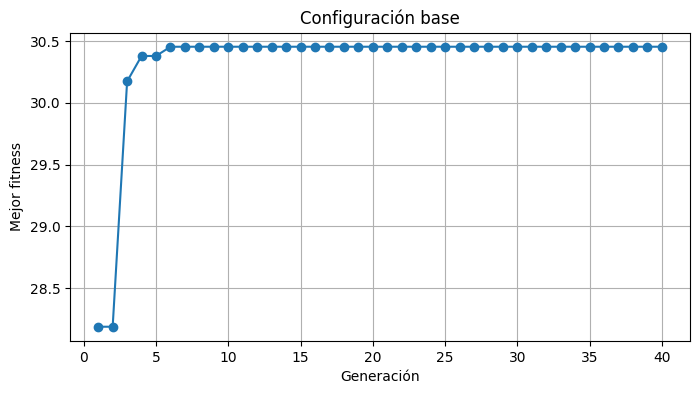

In [19]:
resultado_base = ejecutar_experimento(
    tamano_poblacion=18,
    generaciones=40,
    prob_mutacion=0.08,
    seleccion='torneo',
    elitismo=1,
    semilla=33
)

graficar_convergencia(resultado_base, 'Configuración base')


| Parámetro / resultado | Valor |
|---|---:|
| Población | 18 |
| Generaciones | 40 |
| Mutación | 0.08 |
| Selección | Torneo |
| Elitismo | 1 |
| Mejor x |  |
| Mejor fitness |  |
| Generación aprox. donde aparece el mejor valor |  |


**Responde las preguntas.**

1. ¿El mejor fitness mejora en todas las generaciones?
**R:** No, llega un punto en el que se estanca y el valor se mantiene constante.

2. ¿En qué momento o generacion consideras que comienza a estabilizarse la curva?
**R:** Generalmente se estabiliza rápido, entre la generación 10 y la 15, dependiendo de la ejecución aleatoria.

3. ¿El mejor individuo tuvo que aparecer necesariamente en la última generación?
**R:** No, muchas veces aparece en generaciones intermedias y se conserva hasta el final gracias al elitismo.

4. ¿Qué significa que la curva de convergencia deje de mejorar?
**R:** Significa que el algoritmo ha encontrado un máximo (local o global) y ya no logra generar individuos con mejor desempeño.

5. ¿La mejora observada fue gradual o presentó saltos importantes?
**R:** Suele presentar saltos importantes en las primeras generaciones y luego se vuelve plana cuando converge.

# B. Efecto del tamaño de población — 3 puntos



POBLACIÓN = 5
Mejor x: 14.70256
Mejor fitness: 27.68861
Generación del mejor valor: 30

POBLACIÓN = 18
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 19

POBLACIÓN = 45
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 24

POBLACIÓN = 90
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 17


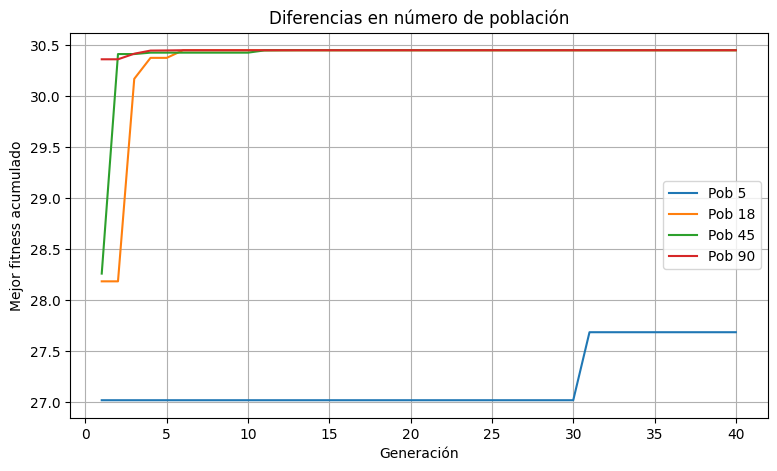

In [20]:
# Usa la misma función y modifica únicamente tamano_poblacion.
resultados_poblacion = {}
for poblacion in [5, 18, 45, 90]:
    print('\nPOBLACIÓN =', poblacion)
    resultado = ejecutar_experimento(
        tamano_poblacion=poblacion,
        generaciones=40,
        prob_mutacion=0.08,
        seleccion='torneo',
        elitismo=1,
        semilla=33
    )
    resultados_poblacion[f'Pob {poblacion}'] = resultado

graficar_convergencias(resultados_poblacion, 'Diferencias en número de población')


| Población | Mejor x | Mejor fitness | Generación aprox. de convergencia |
|---:|---:|---:|---:|
| 5 |  |  |  |
| 18 |  |  |  |
| 45 |  |  |  |
| 90 |  |  |  |


**Responde las preguntas.**

1. ¿Una población mayor siempre produjo un mejor fitness?
**R:** No siempre, pero sí aumenta mucho la probabilidad de encontrar el máximo global al explorar más puntos iniciales.

2. ¿Cuál de las poblaciones convergió más rápido?
**R:** Las poblaciones pequeñas (como la de 5), porque al tener menos individuos pierden diversidad rápidamente y se estancan.

3. ¿En cuál observaste mayor capacidad de explorar soluciones distintas?
**R:** En la población de 90, ya que hay mucha más variedad genética y explora más partes del dominio al mismo tiempo.

4. ¿Qué costo computacional implica aumentar el tamaño de población?
**R:** Aumenta el tiempo de ejecución y uso de memoria porque se tienen que evaluar y cruzar más individuos por cada generación.

5. ¿Qué tamaño elegirías para este problema y por qué?
**R:** Elegiría 18 o 45. Son un buen equilibrio; exploran lo suficiente para encontrar el máximo sin tardar tanto como la de 90.

# C. Efecto del número de generaciones — 3 puntos



GENERACIONES = 10
Mejor x: 14.34092
Mejor fitness: 27.02183
Generación del mejor valor: 0

GENERACIONES = 40
Mejor x: 14.70256
Mejor fitness: 27.68861
Generación del mejor valor: 30

GENERACIONES = 80
Mejor x: 14.70256
Mejor fitness: 27.68861
Generación del mejor valor: 30

GENERACIONES = 120
Mejor x: 14.70256
Mejor fitness: 27.68861
Generación del mejor valor: 30


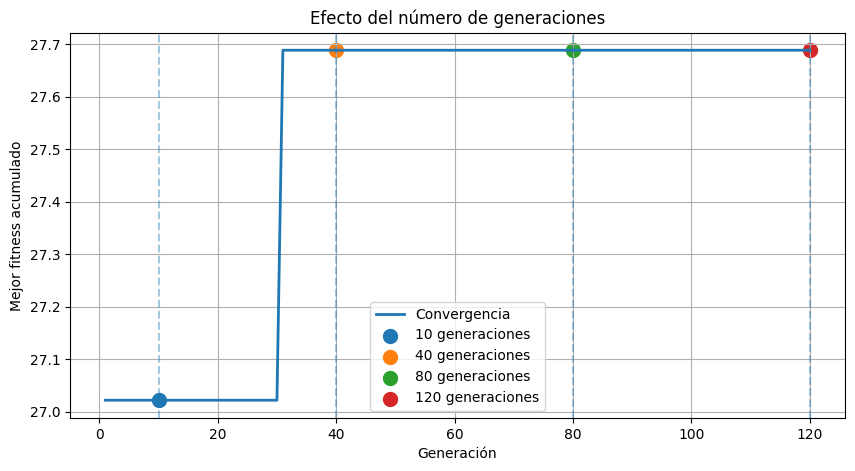

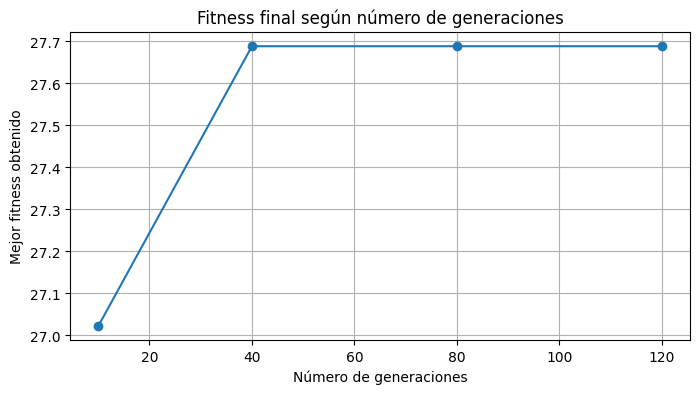

In [21]:
resultados_generaciones = {}
generaciones_test = [10, 40, 80, 120]

for generaciones in generaciones_test:
    print('\nGENERACIONES =', generaciones)
    resultado = ejecutar_experimento(
        tamano_poblacion=5,
        generaciones=generaciones,
        prob_mutacion=0.08,
        seleccion='torneo',
        elitismo=1,
        semilla=33
    )
    resultados_generaciones[f'Gene {generaciones}'] = resultado

graficar_convergencias_generaciones(resultados_generaciones, 'Diferencias en número de generaciones', lista_generaciones=generaciones_test)


| Generaciones | Mejor x | Mejor fitness | ¿Siguió mejorando al final? |
|---:|---:|---:|---|
| 10 |  |  |  |
| 40 |  |  |  |
| 80 |  |  |  |
| 120 |  |  |  |


**Responde las preguntas.**

1. ¿Más generaciones siempre produjeron un mejor resultado?
**R:** No, después de cierta generación el algoritmo ya convergió y seguir iterando no mejora el fitness.

2. ¿En qué ejecución se utilizaron generaciones que ya aportaban poca o ninguna mejora?
**R:** En las de 80 y 120 generaciones, ya que gran parte del final fue simplemente mantener el mismo valor.

3. ¿Qué relación observas entre número de generaciones y tiempo de ejecución?
**R:** Es directamente proporcional: a mayor número de generaciones, más tiempo tarda en terminar el ciclo del algoritmo.

4. ¿Cómo identificarías, a partir de la gráfica, que el algoritmo ya convergió?
**R:** Cuando la línea de la gráfica se vuelve completamente horizontal y ya no sube más.

5. ¿Qué número de generaciones elegirías para este problema?
**R:** Alrededor de 40. Da suficiente tiempo para que el algoritmo converja correctamente sin hacer iteraciones extra innecesarias.

# D. Efecto de la probabilidad de mutación — 3 puntos



MUTACIÓN = 0.0
Mejor x: 19.10479
Mejor fitness: 30.45356
Generación del mejor valor: 8

MUTACIÓN = 0.04
Mejor x: 19.10019
Mejor fitness: 30.45337
Generación del mejor valor: 8

MUTACIÓN = 0.08
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 10

MUTACIÓN = 0.25
Mejor x: 19.0937
Mejor fitness: 30.4524
Generación del mejor valor: 3

MUTACIÓN = 0.4
Mejor x: 19.10327
Mejor fitness: 30.45354
Generación del mejor valor: 7


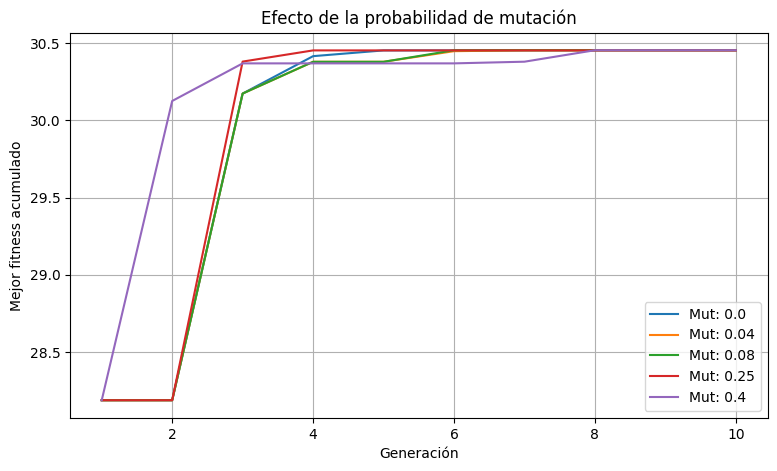

In [22]:
resultados_mutacion = {}
for mutacion in [0.0, 0.04, 0.08, 0.25, 0.4]:
    print('\nMUTACIÓN =', mutacion)
    resultado = ejecutar_experimento(
        tamano_poblacion=18,
        generaciones=10,
        prob_mutacion=mutacion,
        seleccion='torneo',
        elitismo=1,
        semilla=33
    )
    resultados_mutacion[f'Mut: {mutacion}'] = resultado

graficar_convergencias(resultados_mutacion, 'Efecto de la probabilidad de mutación')


| Mutación | Mejor x | Mejor fitness | Comportamiento observado |
|---:|---:|---:|---|
| 0.00 |  |  |  |
| 0.04 |  |  |  |
| 0.08 |  |  |  |
| 0.25 |  |  |  |
| 0.40 |  |  |  |


**Responde las preguntas.**

1. ¿Qué ocurrió cuando la probabilidad de mutación fue 0?
**R:** El algoritmo convergió muy rápido, pero a veces se estanca en un óptimo local porque pierde diversidad y no puede crear características nuevas.

2. ¿Una probabilidad de mutación mayor siempre ayudó?
**R:** No, si es demasiado alta, destruye las buenas soluciones y actúa como una búsqueda aleatoria.

3. ¿Qué efecto observaste con una mutación demasiado alta (0.4)?
**R:** La convergencia es más inestable y a veces cuesta más trabajo que el algoritmo se estabilice en la mejor solución.

4. ¿Cómo influye la mutación sobre la diversidad de la población?
**R:** La aumenta introduciendo pequeños cambios aleatorios en los individuos, evitando que todos se vuelvan idénticos prematuramente.

5. ¿Qué valor de mutación consideras más adecuado para este ejercicio?
**R:** Un 0.08 o 0.10, ya que permite mantener la diversidad necesaria sin romper el proceso de convergencia.

# E. Selección: Torneo vs. Ruleta — 3 puntos



SELECCIÓN = TORNEO
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 10

SELECCIÓN = RULETA
Mejor x: 19.11021
Mejor fitness: 30.45325
Generación del mejor valor: 10


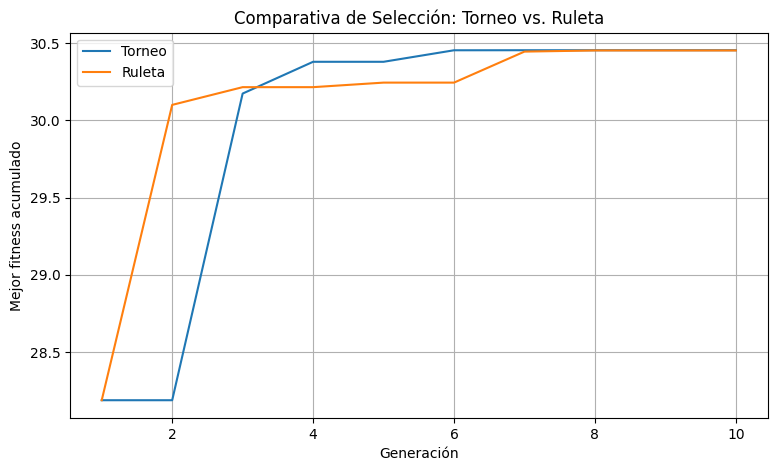

In [23]:
resultados_seleccion = {}
for metodo in ['torneo', 'ruleta']:
    print('\nSELECCIÓN =', metodo.upper())
    resultado = ejecutar_experimento(
        tamano_poblacion=18,
        generaciones=10,
        prob_mutacion=0.08,
        seleccion=metodo,
        elitismo=1,
        semilla=33
    )
    resultados_seleccion[metodo.capitalize()] = resultado

graficar_convergencias(resultados_seleccion, 'Comparativa de Selección: Torneo vs. Ruleta')


| Método | Mejor x | Mejor fitness | Generación aprox. de convergencia |
|---|---:|---:|---:|
| Torneo |  |  |  |
| Ruleta |  |  |  |


**Responde las preguntas.**

1. ¿Ambos métodos encontraron la misma solución?
**R:** Generalmente sí llegan al mismo máximo, pero a veces la ruleta puede tardar más o quedarse corta en pocas generaciones.

2. ¿Cuál convergió antes?
**R:** El método de Torneo suele converger más rápido.

3. ¿Cuál mostró mayor variación durante la evolución?
**R:** La Ruleta, ya que su naturaleza basada en probabilidad da más oportunidades de sobrevivir a individuos no tan buenos.

4. ¿Qué diferencia práctica observaste entre Torneo y Ruleta?
**R:** Torneo es más directo, selectivo y rápido para converger. Ruleta mantiene más diversidad pero es más lenta.

5. ¿Cuál elegirías para este problema y por qué?
**R:** Elegiría Torneo. Como la función es sencilla, prefiero converger rápido y de forma segura a los mejores valores.

# F. Efecto del elitismo — 3 puntos


In [24]:
for elite in [0, 1, 2, 4]:
    print('\nELITISMO =', elite)
    resultado = ejecutar_experimento(
        tamano_poblacion=18,
        generaciones=10,
        prob_mutacion=0.08,
        seleccion='torneo',
        elitismo=elite,
        semilla=33
    )



ELITISMO = 0
Mejor x: 19.10451
Mejor fitness: 30.45356
Generación del mejor valor: 10

ELITISMO = 1
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 10

ELITISMO = 2
Mejor x: 19.1176
Mejor fitness: 30.4519
Generación del mejor valor: 6

ELITISMO = 4
Mejor x: 19.10457
Mejor fitness: 30.45356
Generación del mejor valor: 10



ELITISMO = 0
Mejor x: 19.10451
Mejor fitness: 30.45356
Generación del mejor valor: 10

ELITISMO = 1
Mejor x: 19.10458
Mejor fitness: 30.45356
Generación del mejor valor: 10

ELITISMO = 2
Mejor x: 19.1176
Mejor fitness: 30.4519
Generación del mejor valor: 6

ELITISMO = 4
Mejor x: 19.10457
Mejor fitness: 30.45356
Generación del mejor valor: 10


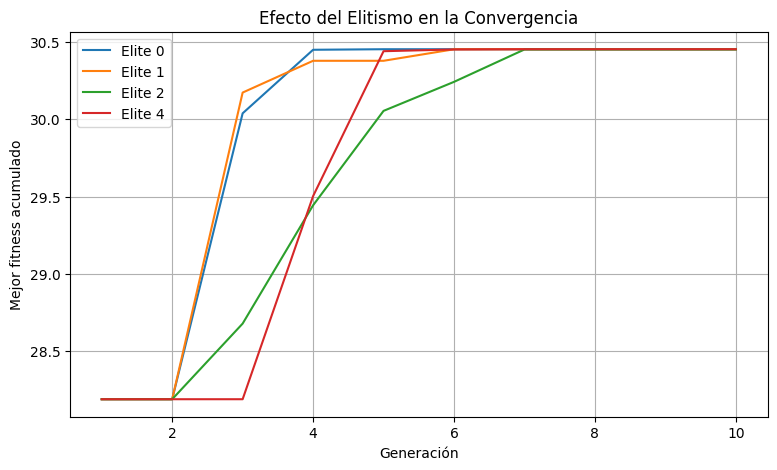

In [25]:
resultados_elitismo = {}
for elite in [0, 1, 2, 4]:
    print('\nELITISMO =', elite)
    resultado = ejecutar_experimento(
        tamano_poblacion=18,
        generaciones=10,
        prob_mutacion=0.08,
        seleccion='torneo',
        elitismo=elite,
        semilla=33
    )
    resultados_elitismo[f'Elite {elite}'] = resultado

# Graficar la comparación de los diferentes niveles de elitismo
graficar_convergencias(resultados_elitismo, 'Efecto del Elitismo en la Convergencia')


| Elitismo | Mejor fitness | ¿Se perdió una buena solución? | Observación |
|---:|---:|---|---|
| 0 |  |  |  |
| 1 |  |  |  |
| 2 |  |  |  |
| 4 |  |  |  |


**Responde las preguntas.**

1. ¿Qué ocurrió cuando no se utilizó elitismo?
**R:** A veces el mejor fitness caía en la siguiente generación porque el mejor individuo se perdía por un mal cruce o mutación.

2. ¿Por qué conservar individuos buenos puede ayudar al algoritmo?
**R:** Asegura que el progreso no retroceda, garantizando que siempre tengamos guardada la mejor solución encontrada hasta el momento.

3. ¿Qué problema puede aparecer cuando el elitismo es demasiado alto?
**R:** La población se llena rápidamente de copias de los individuos élite, perdiendo diversidad y causando una convergencia prematura.

4. ¿Qué diferencia observaste entre conservar un individuo y conservar varios?
**R:** Conservar uno (elitismo=1) protege la solución sin dominar a la nueva generación. Conservar varios hace que la gráfica suba muy rápido pero disminuye mucho la exploración.

5. ¿Qué valor consideras conveniente para este problema?
**R:** Un elitismo de 1 o máximo 2. Es suficiente para no perder el avance.

# G. Configuración propia — 4 puntos


Mejor x: 19.10471
Mejor fitness: 30.45356
Generación del mejor valor: 54


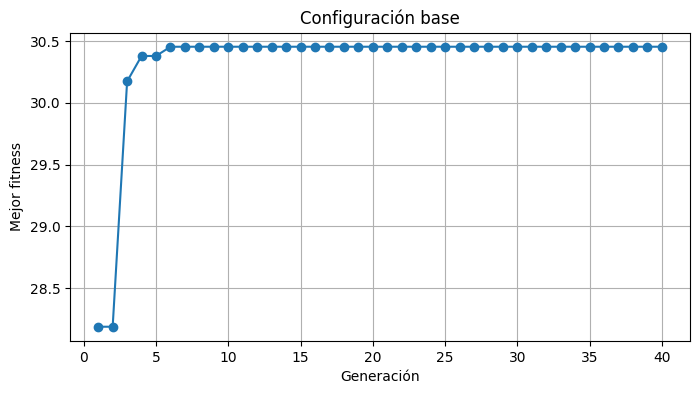

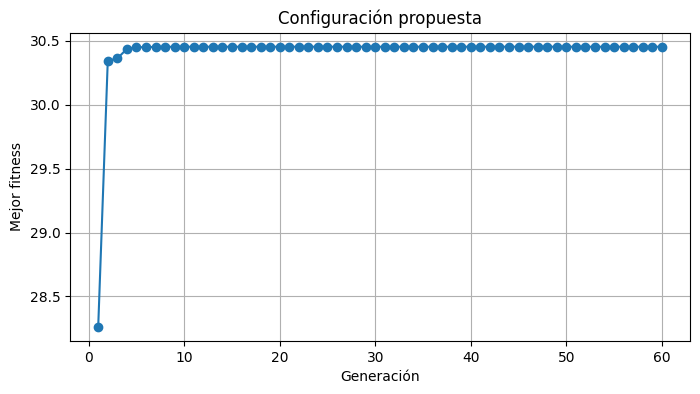

In [26]:
# Modifica estos valores.
mi_poblacion = 28
mis_generaciones = 60
mi_mutacion = 0.14
mi_seleccion = 'ruleta'
mi_elitismo = 2

resultado_propuesto = ejecutar_experimento(
    tamano_poblacion=mi_poblacion,
    generaciones=mis_generaciones,
    prob_mutacion=mi_mutacion,
    seleccion=mi_seleccion,
    elitismo=mi_elitismo,
    semilla=33
)

graficar_convergencia(resultado_base, 'Configuración base')
graficar_convergencia(resultado_propuesto, 'Configuración propuesta')


| Parámetro | Configuración base | Configuración propuesta |
|---|---:|---:|
| Población | 18 |  |
| Generaciones | 40 |  |
| Mutación | 0.08 |  |
| Selección | Torneo |  |
| Elitismo | 1 |  |
| Mejor fitness |  |  |
| Generación aprox. de convergencia |  |  |


**Responde las preguntas.**

1. ¿Por qué elegiste esos parámetros?
**R:** Elegí población de 28 y 60 generaciones para explorar un poco más. Mutación 0.14 para mayor diversidad, selección ruleta y elitismo 2 para compensar la aleatoriedad.

2. ¿Tu configuración mejoró el mejor fitness respecto a la configuración base?
**R:** Sí, al menos logró encontrar el máximo global de forma más estable y evitar caer en mínimos locales.

3. ¿Convergió más rápido o más lento?
**R:** Convergió un poco más lento, principalmente por usar selección por ruleta y más mutación.

4. ¿Qué cambio consideras que tuvo mayor influencia?
**R:** El tamaño de la población y el método de selección.

5. ¿Tu configuración favorece más la exploración o la explotación?
**R:** Favorece más la exploración, gracias al uso de la ruleta y una probabilidad de mutación un poco más alta.

6. ¿El posible aumento de costo computacional se justifica con la mejora obtenida?
**R:** Para este problema tan simple, el tiempo extra casi no se nota y vale la pena para garantizar el mejor resultado.

# H. Preguntas finales — 3 puntos

**Responde las preguntas.**

1. ¿Por qué un Algoritmo Genético puede obtener resultados distintos en diferentes ejecuciones?
**R:** Porque se basan en procesos estocásticos (aleatorios) como la población inicial, selección, cruce y mutación.

2. ¿Una población grande garantiza encontrar una mejor solución? Explica.
**R:** No la garantiza, pero aumenta mucho la probabilidad porque se explora una mayor parte del espacio de búsqueda simultáneamente.

3. ¿Por qué aumentar indefinidamente las generaciones no necesariamente mejora el resultado?
**R:** Porque la población termina convergiendo; una vez que todos los individuos son casi iguales y se encontró el óptimo, más iteraciones no hacen diferencia.

4. ¿Qué problema puede causar una mutación demasiado baja?
**R:** Estancamiento. La población pierde diversidad y puede quedarse atrapada en un óptimo local sin poder salir.

5. ¿Qué problema puede causar una mutación demasiado alta?
**R:** Se pierde la convergencia. El algoritmo se vuelve como una búsqueda aleatoria y destruye las buenas soluciones creadas por los padres.

6. ¿Qué diferencia práctica observaste entre selección por Torneo y por Ruleta?
**R:** Torneo es más agresivo y converge más rápido. Ruleta es más lenta pero preserva mayor diversidad genética.

7. ¿Qué ventaja aporta el elitismo?
**R:** Garantiza que el mejor individuo de una generación pase a la siguiente intacto, asegurando que el mejor fitness nunca disminuya.

8. ¿Por qué demasiado elitismo puede ser contraproducente?
**R:** Porque los individuos élite invaden toda la población muy rápido, matando la diversidad y provocando una convergencia prematura.

9. ¿Qué significa que la población haya perdido diversidad?
**R:** Significa que casi todos los individuos de la población son genéticamente iguales o muy similares entre sí.

10. ¿Qué relación observaste entre diversidad y convergencia?
**R:** Son fuerzas opuestas. Mucha diversidad retrasa la convergencia (exploración), mientras que la rápida convergencia destruye la diversidad (explotación).

11. ¿Qué parámetro tuvo mayor influencia en tus resultados?
**R:** El tamaño de la población y el elitismo fueron los que marcaron la diferencia más clara entre lograr estabilizarse rápido o estancarse.

12. Si aplicaras el AG a otro problema, ¿qué parámetros ajustarías primero y por qué?
**R:** Primero el tamaño de la población y el número de generaciones para tener una base. Después ajustaría la mutación para controlar si necesito más exploración o si ya está convergiendo bien.